# 演習2：測定から分子のエネルギー差を推定する

**できるようになること**：測定結果を取得する／推定を更新する／不確かさと限界を説明する。

配布データは**回路から生成した模擬測定データ**で、IBM実機の測定結果ではありません。グラフでも出所を明記します。
実機結果が弱い・間に合わない場合も、このデータで解析を練習できます。

In [1]:
# GitHub → Colab / ローカルの共通セットアップ
import sys, subprocess, importlib.util
from pathlib import Path
GITHUB_REPOSITORY = "https://github.com/QS-laboratory/IBM_handson.git"
GITHUB_REF = "main"
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "qiskit==2.4.1", "qiskit-ibm-runtime==0.43.1", "pylatexenc==2.10"], check=True)
    checkout = Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git", "clone", GITHUB_REPOSITORY, str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "fetch", "origin", GITHUB_REF, "--depth", "1"], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--detach", "FETCH_HEAD"], check=True)
    WORKSHOP_ROOT = checkout / "hands_on"
else:
    candidates = [Path.cwd(), Path.cwd()/"hands_on", Path.cwd().parent]
    WORKSHOP_ROOT = next(p for p in candidates if (p/"src/workshop.py").exists())
sys.path.insert(0, str(WORKSHOP_ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import *
import qiskit
print("Qiskit:", qiskit.__version__)
print("教材:", WORKSHOP_ROOT)
print("実機への送信は、明示的に有効化したセルだけが行います。")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def show_circuit(qc):
    try:
        figure = qc.draw("mpl", fold=90)
        display(figure)
        plt.close(figure)
    except ImportError:
        print(qc.draw("text", fold=90))

Qiskit: 2.4.1
教材: /Users/sato/project/FTQC_HandsOn/hands_on
実機への送信は、明示的に有効化したセルだけが行います。


## A. 配布データで始める
`compact_ideal`は回路近似と有限ショットを含み、実機ノイズは含みません。
`compact_depolarized`はさらに教材用の一様な脱分極ノイズを加えたもので、IBM実機の詳細なノイズ模型ではありません。

In [2]:
EXAMPLE_FILE = "ethylene_compact_depolarized.json"
data = validate_counts(read_json(WORKSHOP_ROOT / "data/example_results" / EXAMPLE_FILE))
meta, arrays = load_model(data["molecule"])
print("DATA SOURCE:",data["source"])
print("Molecule:",data["molecule"],"variant:",data["variant"])
print("Noise model:",data.get("noise_model", "Actual raw counts; not a simulated noise model"))

DATA SOURCE: simulated_counts
Molecule: ethylene variant: compact
Noise model: {'name': 'global_depolarization_after_circuit', 'rate': 0.15, 'not_ibm_measurements': True}


## B. 自分のIBM実機結果を使う場合（任意）
配布データで進める場合は、この節のフラグをFalseのままにします。
演習1で保存した `..._submission.json` をアップロードし、下の `RECORD_FILE` にそのパスを指定します。
Colab左側のファイル欄からアップロードできます。実機で計算が完了していない場合は、待ってから結果取得だけを再実行します。

In [3]:
# 接続を試すときだけTrueに変更。APIキーをコードや出力へ書かないでください。
CONNECT_IBM = False
INSTANCE_CRN = ""  # 今回利用できる所属企業の枠、または講師が案内するFlex枠
BACKEND_NAME = ""  # 接続後、利用可能な実機から講師と相談して指定
service = None
if CONNECT_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    if not INSTANCE_CRN:
        raise ValueError("利用権限のあるインスタンスのCRNを指定してください")
    if IS_COLAB:
        from google.colab import userdata
        api_key = userdata.get("IBM_QUANTUM_API_KEY")
    else:
        from getpass import getpass
        api_key = getpass("IBM Quantum API key: ")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key, instance=INSTANCE_CRN)
    del api_key
    print("利用可能な実機:", [b.name for b in service.backends(operational=True, simulator=False)])
else:
    print("IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。")

IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。


In [4]:
USE_IBM_RESULTS = False
RECORD_FILE = "outputs/team01_submission.json"
if USE_IBM_RESULTS:
    if service is None: raise ValueError("IBMへ再接続してください")
    record=read_json(RECORD_FILE)
    data=fetch_ibm(record,service)
    write_json(OUTPUT_DIR/f"{data['team']}_results.json",data)
    meta, arrays=load_model(data["molecule"])
    print("DATA SOURCE:",data["source"],"backend:",data["backend"])

## 測定したものを確認する

各条件で、全ビットが0だった回数kと総ショット数nを取り出します。観測確率はk/nです。
成功・失敗の集計は実際の整数回数を使います。誤差緩和後の擬似確率を整数回数として扱いません。
Fire Opalの結果を取り込むには、その出力の統計的な扱いを別途設計する必要があります。

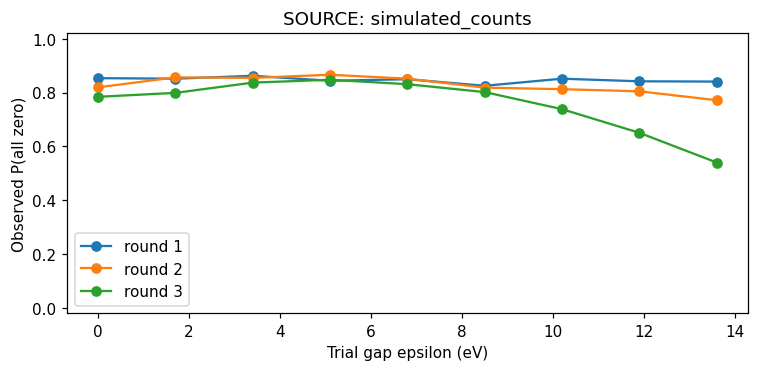

In [5]:
fig, ax=plt.subplots(figsize=(7,3.5))
for iteration in sorted({r["iteration"] for r in data["rows"]}):
    rows=[r for r in data["rows"] if r["iteration"]==iteration]
    x=np.array([r["epsilon_hartree"] for r in rows])*HARTREE_TO_EV
    p=np.array([r["successes"]/r["shots"] for r in rows])
    ax.plot(x,p,"o-",label=f"round {iteration}")
ax.set(xlabel="Trial gap epsilon (eV)",ylabel="Observed P(all zero)",title="SOURCE: "+data["source"],ylim=(-.02,1.02))
ax.legend(); plt.tight_layout(); plt.show()

## 推定を更新する

求めたい値を $\Delta E$ とします。理想的には
$p=(1+\cos[(\Delta E-\varepsilon)t])/2$。
仮の $\Delta E$ ごとに、実際の回数kがどのくらい起こりやすいかを二項分布で計算します。

**事後分布 ∝ 事前分布 × 測定結果の尤度**。
今回は0〜0.5 Hartreeの一様な事前分布を使います。この範囲には別の周期の解が入りにくい時間設定を使います。
参照値を中心に事前分布を狭めることはしません。

実機の信号低下に対応するため、背景とコントラストも不明な量として候補を置き、データと共に更新してから平均化します。
モデルは $p=b+v(1+\cos[(\Delta E-\varepsilon)t])/2$ です。
背景bとコントラストvが全ラウンドで共通という簡略化を含みます。実機では回路の深さで変わるため、適合を確認する必要があります。

表示区間は**この事前分布と尤度モデルを仮定した95%ベイズ信用区間**です。模型・基底・回路近似の誤差をすべて含む区間ではありません。

Round 1: 4.942 eV, conditional 95% interval [2.310, 7.786]
Round 2: 4.689 eV, conditional 95% interval [3.947, 5.438]
Round 3: 4.746 eV, conditional 95% interval [4.481, 4.995]
Classical reference for this CASCI model: 4.783703474310449 eV
Scan variation detected: True
Exploratory model check: 0.47294661522176074


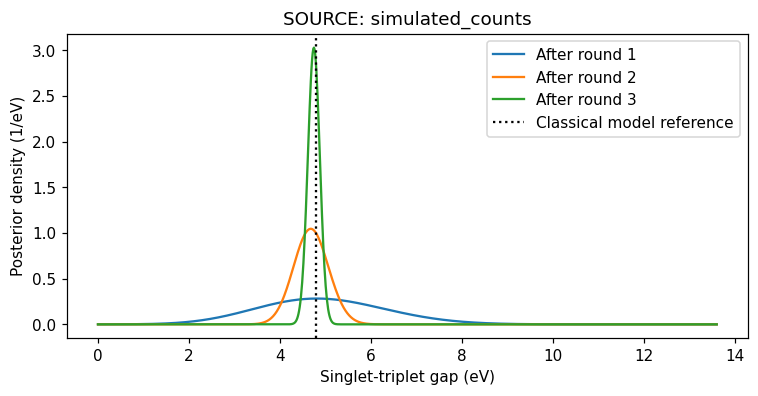

In [6]:
history=infer_gap(data,noise_aware=True)
fig=plot_posterior(history,reference=meta["gap_hartree"])
fig.axes[0].set_title("SOURCE: "+data["source"])
plt.show()
for row in history:
    low,high=np.array(row["ci95_hartree"])*HARTREE_TO_EV
    print(f"Round {row['iteration']}: {row['mean_hartree']*HARTREE_TO_EV:.3f} eV, conditional 95% interval [{low:.3f}, {high:.3f}]")
    if row["edge_mass"]>.1: print("探索範囲の端に質量があります。探索範囲とモデルを確認してください。")
print("Classical reference for this CASCI model:",meta["gap_ev"],"eV")
diagnostics=inference_diagnostics(data,history)
print("Scan variation detected:",diagnostics["detectable_scan_variation"])
print("Exploratory model check:",diagnostics["approx_model_tail_probability"])
if not diagnostics["detectable_scan_variation"]:
    print("信号を確認できません。狭い推定区間を成功と判断せず、測定データを再点検してください。")
if diagnostics["model_mismatch_warning"]:
    print("共通の背景・コントラストという尤度モデルとのずれが疑われます。区間を過信しないでください。")

## 誤差を3つに分ける

| 要因 | 比較の仕方 | ショットを増やせば消えるか |
|---|---|---|
| 有限ショットの統計変動 | 同じ回路・同じノイズ模型で測定回数だけ変える | 小さくなる |
| 回路近似による偏り | ノイズなしのreference回路とcompact回路を比較 | 消えない |
| 実機ノイズ | 同じ回路の理想計算と実機の測定を比較 | 一般には消えない |

以下では配布の模擬測定を使ってノイズを無視した推定と比較します。
**区間が狭いことと、正しいことは別です。** 信号が消えた結果を、無理に成功した推定へ変換しないでください。

In [7]:
simple=infer_gap(data,noise_aware=False)[-1]
aware=history[-1]
for title,row in [("Ideal likelihood",simple),("Background/contrast marginalized",aware)]:
    print(title,"mean/eV",round(row["mean_hartree"]*HARTREE_TO_EV,3),
          "interval/eV",np.round(np.array(row["ci95_hartree"])*HARTREE_TO_EV,3))
# 生データを見てから区間を解釈します。複雑なノイズや近似誤差まで補正できたことにはなりません。
summary_result={"source":data["source"],"molecule":data["molecule"],"variant":data["variant"],
                "mean_hartree":aware["mean_hartree"],"conditional_ci95_hartree":aware["ci95_hartree"],
                "likelihood":"binomial with shared background/visibility nuisance grid",
                "limitations":"conditional on likelihood and scan range; excludes molecular model error"}
write_json(OUTPUT_DIR/"inference_summary.json",summary_result)

Ideal likelihood mean/eV 0.727 interval/eV [0.686 0.755]
Background/contrast marginalized mean/eV 4.746 interval/eV [4.481 4.995]


### ショット数を変える（時間があるチーム向け）
教材の同じ回路とノイズ模型で、ショット数だけを変えます。
同じ一回の模擬実験で、区間幅が必ず単調に減ると保証されるわけではありません。

In [8]:
RUN_SHOT_COMPARISON = False
if RUN_SHOT_COMPARISON:
    for shots in [256,1024,4096]:
        simulated=simulate_results(make_plan("ethylene",shots=shots),seed=19,noise_rate=.15)
        last=infer_gap(simulated)[-1]
        print("Shots per circuit:",shots,"interval width/eV:",np.diff(last["ci95_hartree"])[0]*HARTREE_TO_EV)

## チーム討論

1. 何の分子の、どの2状態の差を求めたか。実験値と比べる前に何を確認するか。
2. 短い回路と長い回路で、どの指標が良くなり、どの指標が悪くなったか。
3. 事後分布が狭くなったら成功と言えるか。基準値からのずれと整合するか。
4. 実機の信号が弱かった場合、回路を浅くする・時間を短くする・ショットを増やす、どれを試すか。
5. 活性空間と基底関数を拡大したとき、今日の結果の意味はどう変わるか。

各組は「対象」「実行条件」「分かったこと」「残る課題」を1分で共有してください。

次に詳しく学びたい方は `03_mps_mpo_advanced.ipynb` へ進んでください。